# 03 — Variogramme expérimental et modélisation

## Objectif de ce notebook

Calculer le variogramme expérimental de **Y.Pb** (espace gaussien), ajuster un modèle théorique, étudier l'anisotropie via la carte variographique, et calculer le variogramme directionnel.

## Prérequis

Ce notebook nécessite que l'anamorphose gaussienne ait été réalisée au préalable (notebook **02_anamorphose_gaussienne.ipynb**). Pour des raisons pédagogiques, ce notebook est conçu pour être exécuté **après** le notebook 02 dans le même environnement, ou en relançant les étapes de transformation en tête de notebook.

## Contenu

1. Définition des paramètres du variogramme (nlag, dlag)
2. Nuage de variogramme (Variogram Cloud)
3. Variogramme expérimental omnidirectionnel
4. Ajustement automatique de modèles (sphérique, nugget + sphérique)
5. Ajustement manuel interactif (widget)
6. Comparaison des modèles et choix du meilleur ajustement
7. Carte variographique (étude de l'anisotropie)
8. Variogramme directionnel (2 directions principales)

## Sortie de ce notebook

Le modèle final ajusté (`model_final`) est réutilisé dans le notebook **04_krigeage_simulation.ipynb** pour le krigeage et la simulation.

*Ce notebook correspond à l'Exercice 3 du TD6 (variogramme sur un nuage de points 2D, slide 24), enrichi des notions de modélisation et d'anisotropie du cours.*

**Source** : La structure du calcul et de l'ajustement du variogramme (`VarioParam`, `Vario`, `Model.fit`) s'appuie sur la documentation officielle de gstlearn — [gstlearn.org](https://gstlearn.org/)

## Rappel : recréer le contexte (base `db` avec Y.Pb)

Cette cellule reproduit rapidement les étapes essentielles du notebook 02 (chargement, filtrage, anamorphose) afin que ce notebook puisse être exécuté de façon autonome si besoin.

In [2]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gstlearn as gl
import gstlearn.plot as gp
import ipywidgets as widgets
from ipywidgets import interactive_output

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# Reconstruction du contexte à l'aide de la fonction d'initialisation du module
data_jura, db, anam_hermite = gutils.preparer_db_gaussienne()
print("Contexte reconstruit : base db avec Y.Pb prête pour le variogramme.")


Contexte reconstruit : base db avec Y.Pb prête pour le variogramme.


## 1. Paramètres du variogramme

Les paramètres utilisés pour le calcul du variogramme expérimental sont :

- **Nombre de lags** : 17
- **Distance de lag** : 0.291066 km
- **Tolérance angulaire** : 22.5°

In [35]:
# ---- Définition des paramètres du variogramme ----
# Les paramètres nlag et dlag sont définis ici une seule fois
# et réutilisés dans toutes les sections suivantes :

etendue_x = data_jura["X"].max() - data_jura["X"].min()
etendue_y = data_jura["Y"].max() - data_jura["Y"].min()

diagonale_domaine = np.sqrt(etendue_x**2 + etendue_y**2)
nombre_classe = 17
taille_classe = 0.291066

print(f"Longueur du domaine selon X : {etendue_x:.3f} km")
print(f"Longueur du domaine selon Y : {etendue_y:.3f} km")
print(f"Diagonale du domaine : {diagonale_domaine:.2f} km")
print(f"Nombre de classes (nlag)    : {nombre_classe}")
print(f"Taille d'une classe (dlag) : {taille_classe} km")

Longueur du domaine selon X : 4.294 km
Longueur du domaine selon Y : 5.110 km
Diagonale du domaine : 6.67 km
Nombre de classes (nlag)    : 17
Taille d'une classe (dlag) : 0.291066 km


## 2. Nuage de variogramme (Variogram Cloud) — Y.Pb

Les données sont modélisées comme des échantillons d'une variable
régionalisée **z** — ici le Plomb transformé **Y.Pb** (espace gaussien),
c'est-à-dire des évaluations aux locations x1,...,xn :

$$z_i = z(x_i) : i = 1,...,n$$

Le nuage de variogramme est l'ensemble de **toutes les paires de points**
défini comme :

$$\left\{ \left( \|x_i - x_j\|, \left| z(x_i) - z(x_j) \right|^2 \right) \text{ où } 1 \leq i \leq j \leq n \right\}$$

où :
- $\|x_i - x_j\|$ → distance entre deux points
- $|z(x_i) - z(x_j)|^2$ → différence au carré des valeurs de Y.Pb

Dans gstlearn, les nuages de variogramme sont calculés sous forme de
**grilles**, via les fonctions :
- `gl.VarioParam.createOmniDirection(nlag, dlag)` : paramètres du variogramme omnidirectionnel
- `gl.db_vcloud()` : calcule le nuage de variogramme sous forme de grille


Data Base Grid Characteristics

Data Base Summary
-----------------
File is organized as a regular grid
Space dimension              = 2
Number of Columns            = 4
Total number of samples      = 10000

Grid characteristics:
---------------------
Origin :       0.000      0.000
Mesh   :       0.067      0.029
Number :         100        100

Variables
---------
Column = 0 - Name = rank - Locator = NA
Column = 1 - Name = x1 - Locator = x1
Column = 2 - Name = x2 - Locator = x2
Column = 3 - Name = Cloud.Y.Pb - Locator = NA



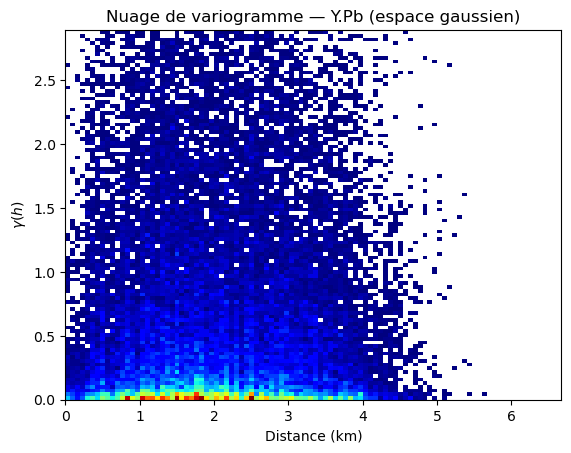

In [36]:
# ---- Nuage de variogramme (Variogram Cloud) — Y.Pb ----

db.setLocator("Y.Pb", gl.ELoc.Z)

varioParamOmni_cloud = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe, dlag=taille_classe
)
grid_cloud_YPb = gl.db_vcloud(db, varioParamOmni_cloud)
print(grid_cloud_YPb)

gp.plot(grid_cloud_YPb, "Cloud.Y.Pb", cmap="jet")
plt.title("Nuage de variogramme — Y.Pb (espace gaussien)")
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.show()

## 3. Variogramme expérimental omnidirectionnel

Le variogramme expérimental omnidirectionnel permet d'analyser la continuité spatiale des concentrations en **Plomb (Pb)** en fonction de la distance entre les échantillons. Les valeurs obtenues seront ensuite utilisées pour ajuster un modèle théorique du variogramme.

Le variogramme théorique est défini par :

$$\gamma(h) = \frac{1}{2}E\left[(Z(s+h) - Z(s))^2\right]$$

Il est estimé, à partir des $n_h$ paires de points séparées par un vecteur $h$, par le variogramme expérimental :

$$\gamma^*(h) = \frac{1}{2n_h}\sum_{i=1}^{n_h} (Z(s_i+h) - Z(s_i))^2$$

In [37]:
# ---- Calcul du variogramme expérimental omnidirectionnel ----
db.setLocator("Y.Pb", gl.ELoc.Z)
params_vario_omni = gl.VarioParam.createOmniDirection(
    nlag=nombre_classe, dlag=taille_classe, toldis=0.1
)
vario_exp_omni = gl.Vario(params_vario_omni)
err = vario_exp_omni.compute(db)
print(vario_exp_omni)


Variogram characteristics
Number of variable(s)       = 1
Number of direction(s)      = 1
Space dimension             = 2
Variable(s)                 = [Y.Pb]

Variance-Covariance Matrix      0.995

Direction #1
------------
Number of lags              = 17
Direction coefficients      =       1.000      0.000
Direction angles (degrees)  =       0.000
Tolerance on direction      =      90.000 (degrees)
Calculation lag             =       0.291
Tolerance on distance       =      10.000 (Percent of the lag value)

For variable 1
       Rank     Npairs   Distance      Value
          0    115.000      0.013      0.349
          1    211.000      0.290      0.950
          2    274.000      0.581      0.870
          3    466.000      0.873      0.935
          4    402.000      1.165      1.064
          5    657.000      1.456      1.073
          6    793.000      1.752      0.909
          7    619.000      2.041      1.114
          8    363.000      2.325      1.180
          9    44

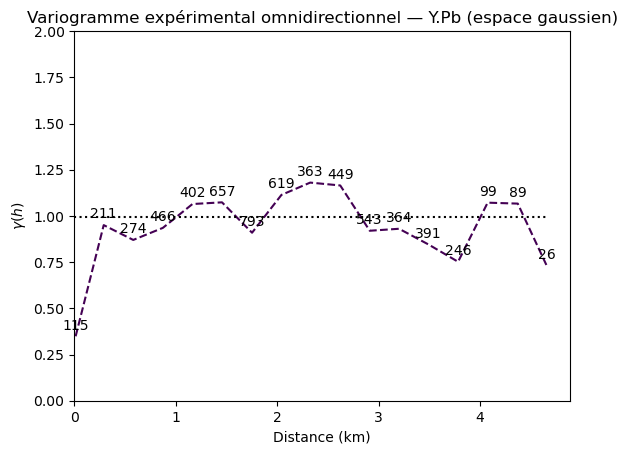

In [38]:
# ---- Affichage du variogramme expérimental omnidirectionnel (avec nombre de paires) ----
ax = gp.varmod(vario_exp_omni, showPairs=True)
ax.set_ylim(0, 2)
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme expérimental omnidirectionnel — Y.Pb (espace gaussien)")
gutils.sauvegarder_figure("fig08_variogramme_experimental.png") 
plt.show()

## 4. Fonction d'affichage des variogrammes ajustés

Pour éviter de répéter le même code d'affichage à chaque modèle testé (sphérique sans nugget, nugget + sphérique, ajustement manuel), une
fonction réutilisable `afficher_variogramme()` est définie ci-dessous. Elle superpose le variogramme expérimental et son modèle théorique
ajusté sur un même graphique.

In [39]:
# ---- Fonction d'affichage des variogrammes (importée de geostat_utils) ----
afficher_variogramme = gutils.afficher_variogramme


## 5. Ajustement automatique du modèle de variogramme

Le modèle est ajusté automatiquement avec la fonction `fit()` de **gstlearn** sur le variogramme expérimental omnidirectionnel. On commence par un modèle **sphérique seul (sans effet de pépite)**, pour observer les limites de cet ajustement : comme les données présentent une discontinuité à l'origine, l'algorithme risque de compenser en réduisant artificiellement la portée. Un effet de pépite sera ajouté à l'étape suivante (5.1) pour corriger cela.

Variance Y.Pb = 0.96


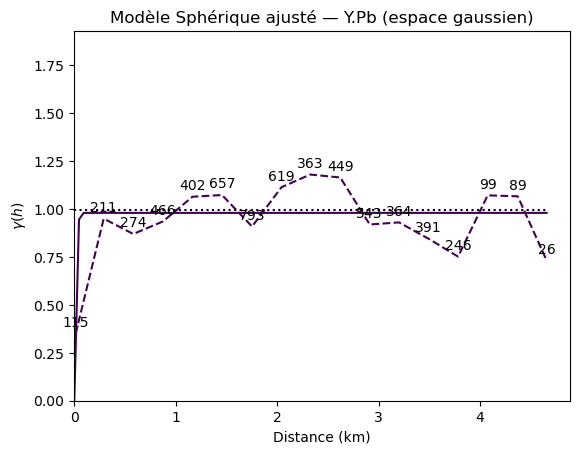


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 1
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Spherical
- Sill         =       0.980
- Range        =       0.055
Total Sill     =       0.980
Known Mean(s)      0.000



In [40]:
#----Ajustement automatique - Modèle Sphérique sans nugget----

variance = np.var(db.getColumn("Y.Pb"), ddof=1)
print(f"Variance Y.Pb = {variance:.2f}")

model_vario_ajuster = gl.Model()
err = model_vario_ajuster.fit(vario_exp_omni, types=[gl.ECov.SPHERICAL])
afficher_variogramme(vario_exp_omni, model_vario_ajuster, "Modèle Sphérique ajusté — Y.Pb (espace gaussien)", variance)

### 5.1 Ajustement automatique avec Nugget + Sphérique

Un effet de pépite est ajouté au modèle sphérique. Le modèle obtenu par ajustement automatique avec la fonction `fit()` de **gstlearn**.

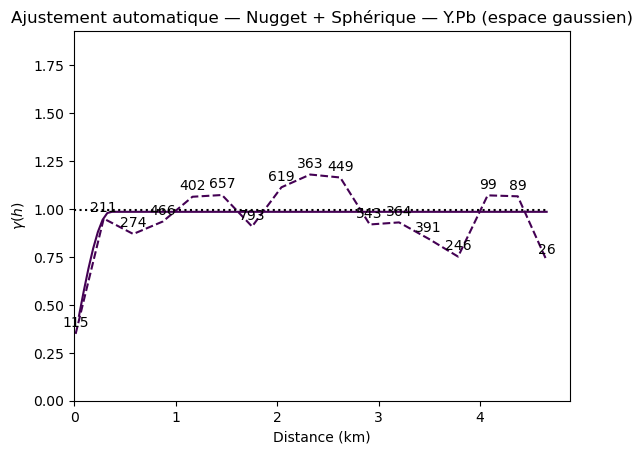


Model characteristics
Space dimension              = 2
Number of variable(s)        = 1
Number of basic structure(s) = 2
Number of drift function(s)  = 0
Number of drift equation(s)  = 0

Covariance Part
---------------
Nugget Effect
- Sill         =       0.310
Spherical
- Sill         =       0.675
- Range        =       0.353
Total Sill     =       0.986
Known Mean(s)      0.000



In [41]:
# ---- Ajustement automatique - Nugget + Sphérique ----
model_nugget_spherique = gl.Model()
err = model_nugget_spherique.fit(vario_exp_omni, types=[gl.ECov.NUGGET, gl.ECov.SPHERICAL])
afficher_variogramme(vario_exp_omni, model_nugget_spherique,
    "Ajustement automatique — Nugget + Sphérique — Y.Pb (espace gaussien)", variance,
    chemin_fichier="fig09_nugget_spherique_auto.png")

## 5.2 Ajustement manuel interactif du variogramme

Le widget ci-dessous permet de régler **manuellement** les paramètres du modèle de variogramme :

- **Modèle** : Sphérique, Exponentiel ou Gaussien
- **Nugget** : effet de pépite (proportion de la variance)
- **Portée** : distance à laquelle le variogramme atteint le palier

In [42]:
calage = gutils.creer_widget_calage_variogramme(
    vario_exp_omni, variance,
    facteur_correction=0.991462
)
model_final = calage.model

## 5.3 Comparaison des trois modèles et choix du meilleur ajustement

Trois modèles ont été testés pour ajuster le variogramme expérimental de **Y.Pb** :

| Modèle | Nugget | Portée (km) |
|---|---|---|
| **Nugget + Sphérique** | 0.21 | 0.60 |
| **Nugget + Exponentiel** | 0.15 | 0.86 |
| **Nugget + Gaussien** | 0.15 | 0.70 |

Le modèle retenu (Nugget + Sphérique) s'écrit :

$$\gamma(h) = \begin{cases} 0 & h = 0 \\ c_0 + c_s\left[\dfrac{3}{2}\left(\dfrac{h}{r}\right) - \dfrac{1}{2}\left(\dfrac{h}{r}\right)^3\right] & 0 < h \leq r \\ c_0 + c_s & h > r \end{cases}$$

où $c_0$ est l'effet de pépite (nugget), $c_s$ le palier partiel, et $r$ la portée.

Le modèle retenu est **Nugget + Sphérique** car il présente la meilleure continuité spatiale et s'ajuste bien au variogramme expérimental. Ce
modèle (`model_final`) sera utilisé pour le **krigeage** dans le notebook suivant.

Avant de continuer, s'assurer que le widget ci-dessus a bien été réglé sur **Spherique / Nugget = 0.21 / Portée = 0.60** pour que
`model_final` corresponde au modèle retenu.

## 6. Carte variographique (Variogram Map)

La carte variographique représente les valeurs du variogramme dans **toutes les directions simultanément** (0° ≤ θ < 360°). Elle permet d'identifier les directions d'anisotropie de **Y.Pb**. En Python, elle est calculée avec la fonction `gl.db_vmap()`.

- **Nombre de lags** : 17
- **Distance de lag** : 0.291066 km
- **Nombre minimum de paires** : 0

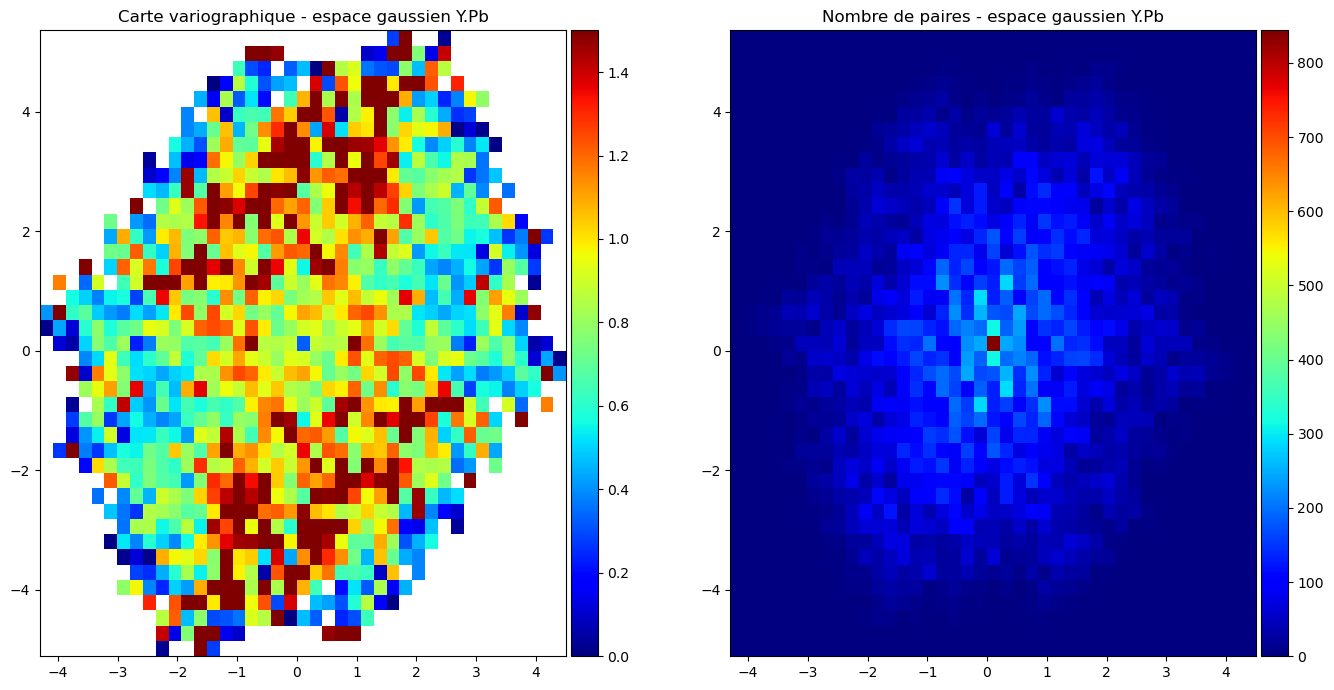

In [43]:
# ---- Affichage de la carte variographique (Variogram Map) ----
# Affiche les valeurs du variogramme dans toutes les directions
# simultanément pour identifier les directions d'anisotropie

db.setLocator("Y.Pb", gl.ELoc.Z)

grid_map = gl.db_vmap(db)
fig, ax = gp.init(1, 2, figsize=(14, 7), flagEqual=True)
ax[0].raster(grid_map, flagLegend=True, cmap="jet", vmin=0, vmax=1.5)
ax[0].decoration(title="Carte variographique - espace gaussien Y.Pb")

# ---- Carte du nombre de paires ----

ax[1].raster(grid_map, name="VMAP.Y.Pb.Nb", flagLegend=True, cmap="jet")
ax[1].decoration(title="Nombre de paires - espace gaussien Y.Pb")
plt.tight_layout()
gutils.sauvegarder_figure("figure10_carte_variographique") 
plt.show()

### Commentaire sur la carte variographique

- Le **centre est bleu foncé**, indiquant une faible variance à courte distance, signifiant une bonne continuité spatiale de Y.Pb 

- Les **bords sont plus clairs** (vert/rouge), montrant une grande variance à longue distance

- La carte est **légèrement allongée** dans la direction **Nord-Ouest/Sud-Est (135°)**, ce qui confirme l'anisotropie observée  dans le variogramme directionnel ci-dessous

## 7. Variogramme directionnel

Les paramètres utilisés sont les mêmes que pour le variogramme omnidirectionnel :

- **Nombre de lags** : 17
- **Distance de lag** : 0.291066 km
- **Tolérance angulaire** : 22.5°

Les 2 directions principales identifiées manuellement sur la carte variographique :

- **Azimuth 45°** (Nord-Est / Sud-Ouest) : direction perpendiculaire
- **Azimuth 135°** (Nord-Ouest / Sud-Est) : direction de plus grande continuité

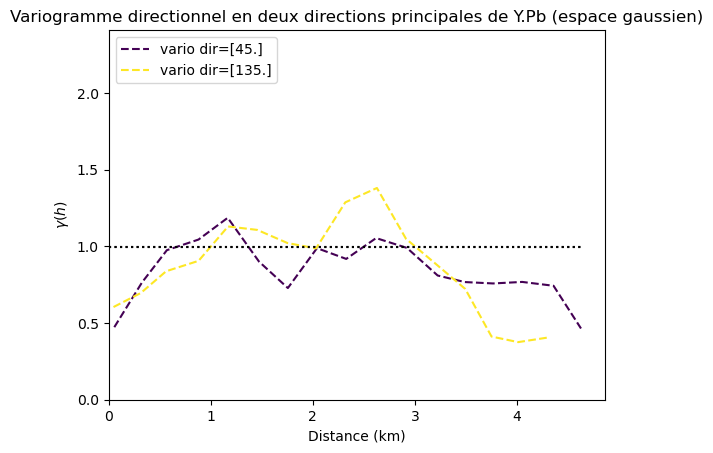

In [44]:
# ---- Variogramme directionnel en deux directions principales (méthode manuelle) ----

varioparam_dir = gl.VarioParam()
direction_45  = gl.DirParam.create(nlag=nombre_classe, dlag=taille_classe, tolang=22.5, codir=[1, 1])
direction_135 = gl.DirParam.create(nlag=nombre_classe, dlag=taille_classe, tolang=22.5, codir=[-1, 1])

varioparam_dir.addDir(direction_45)
varioparam_dir.addDir(direction_135)

vario_exp_dir = gl.Vario(varioparam_dir)
err = vario_exp_dir.compute(db)

# ---- Affichage ----
gp.varmod(vario_exp_dir)
plt.ylim(0, variance * 2.5)
plt.legend(loc='upper left')
plt.xlabel("Distance (km)")
plt.ylabel(r"$\gamma(h)$")
plt.title("Variogramme directionnel en deux directions principales de Y.Pb (espace gaussien)")
gutils.sauvegarder_figure("variogramme_directionnel") 
plt.show()

## Conclusion

Le modèle **Nugget + Sphérique** (`model_final`, nugget=0.21, portée=0.60 km) a été retenu pour représenter la structure spatiale de **Y.Pb**. La carte variographique et le variogramme directionnel confirment une anisotropie modérée dans l'axe Nord-Ouest/Sud-Est.

`model_final` et `db` (avec Y.Pb) sont réutilisés dans le notebook suivant **04_krigeage_simulation.ipynb**, où un voisinage (`neigh`) est créé pour réaliser le krigeage.